# 12. Models that are awkward to write in Pyomo

Pyomo is an algebraic modelling language [hart2011pyomo, bynum2021pyomo]: a model is a set of `Var`, `Param`,
`Constraint` and `Objective` objects, and every expression in it is built from those objects with overloaded
operators. A Pyomo expression is a *symbolic tree*, not a number. That is what lets Pyomo hand the model to SCIP,
Couenne or BARON as a list of algebraic equations, and it is also why ordinary numerical code cannot be used
inside a Pyomo model: a function that expects floats (or arrays), loops a number of times, or calls a compiled
library routine has no way to produce a Pyomo expression.

jaxglobal takes a Python function instead. It traces the function to a jaxpr (JAX's list of primitive
operations, see notebook 01) and computes bounds by evaluating that jaxpr in interval and McCormick arithmetic.
Anything that traces to supported primitives is a model. That makes a few things easy that Pyomo has no direct
form for. This notebook tries four of them, says which worked and which did not, and shows what a Pyomo user
would do instead.

1. A fixed-iteration loop inside the model (`lax.fori_loop`), here the Colebrook friction-factor iteration.
2. Reusing existing `jax.numpy` / `jax.scipy` library functions inside the model.
3. Vectorized linear-algebra code (`einsum`, `@`) with no index sets.
4. A parametric family: the same model solved for several parameter values.

Several of these fail, or only partly work, in jaxglobal today; the failures are shown, not hidden. Solver
limits for everything: relative gap 1e-4, at most 60 s.

In [1]:
import numpy as np
import pyomo.environ as pyo

from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from jaxglobal import export, relax  # importing jaxglobal enables float64, before any JAX computation

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
# one color and marker per solver, as in notebook 08
STYLE = {"scip": (BLUE, "s"), "couenne": (AQUA, "D"), "baron": (YELLOW, "^"), "jaxglobal": (ORANGE, "o")}

## 1. A fixed-iteration loop: Colebrook friction factor

**Background.** The pressure drop of a fluid flowing through a pipe of length $L$ and diameter $D$ is given by
the Darcy–Weisbach equation

$$ \Delta P = f\,\frac{L}{D}\,\frac{\rho v^2}{2}, \qquad v = \frac{4Q}{\pi D^2}, \qquad Re = \frac{\rho v D}{\mu}, $$

with volumetric flow rate $Q$, density $\rho$, viscosity $\mu$ and Reynolds number $Re$. The Darcy friction
factor $f$ of turbulent flow is defined implicitly by the Colebrook equation [colebrook1939turbulent], the
equation behind the Moody chart [moody1944friction]:

$$ \frac{1}{\sqrt f} = -2\log_{10}\!\left(\frac{\varepsilon}{3.7D} + \frac{2.51}{Re\sqrt f}\right), $$

where $\varepsilon$ is the pipe roughness. There is no closed form for $f$ (except through the Lambert $W$
function). In a program one writes $x = 1/\sqrt f$ and iterates the right-hand side as a fixed-point map,

$$ x_{k+1} = g(x_k) = -2\log_{10}\!\left(\frac{\varepsilon}{3.7D} + \frac{2.51\,x_k}{Re}\right), \qquad f \approx 1/x_K^2, $$

started from an explicit approximation, here Haaland's formula

$$ x_0 = -1.8\log_{10}\!\left[\left(\frac{\varepsilon/D}{3.7}\right)^{1.11} + \frac{6.9}{Re}\right]. $$

The map $g$ is a contraction, $|g'(x)| = \frac{2}{\ln 10}\,\frac{2.51/Re}{\varepsilon/(3.7D) + 2.51x/Re} < 1$ for
the values met here, so a few iterations give a good $f$ (the figure below measures how good).

**The problem.** Choose the flow rate $Q \in [10^{-3}, 10^{-2}]$ m³/s and the diameter $D\in[0.02, 0.3]$ m to
maximize revenue minus pumping and pipe cost, written as the minimization

$$ \min_{Q,D}\ \ -4\times10^{5}\,Q \;+\; 0.8\,\frac{\Delta P\,Q}{0.7} \;+\; 2.4\times10^{4}\,D^{1.5}. $$

The first term is revenue proportional to throughput, the second is the pumping power $\Delta P\,Q$ (W) through a
pump of efficiency 0.7 times an energy price, and the third is the pipe cost, growing with diameter. The cost
coefficients are made up for the example; the fluid has density 900 kg/m³ and viscosity 0.05 Pa s, and the pipe is
200 m of commercial steel ($\varepsilon = 4.5\times10^{-5}$ m). Small diameters make pumping expensive
($\Delta P \propto 1/D^5$ at fixed $f$), large ones make the pipe expensive: the optimum is a trade-off.

**Why it is awkward in an algebraic modelling language.** The model contains a loop. Pyomo has no loop
construct that is part of a model; a `for` loop in Python that builds an expression is unrolled at model
construction, and a solver-side iteration does not exist. jaxglobal sees the loop as a `lax.fori_loop` (a
`scan` primitive with a fixed trip count of 4) in the jaxpr.

In [2]:
EPS, RHO, MU, LEN = 4.5e-5, 900.0, 0.05, 200.0


def friction(Re, D, iters=4):
    x0 = -1.8 * jnp.log10((EPS / D / 3.7) ** 1.11 + 6.9 / Re)  # Haaland start for x = 1/sqrt(f)
    x = jax.lax.fori_loop(0, iters, lambda i, x: -2.0 * jnp.log10(EPS / (3.7 * D) + 2.51 * x / Re), x0)
    return 1.0 / x**2


def pipe(x):
    Q, D = x[0], x[1]
    v = 4 * Q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    dP = friction(Re, D) * (LEN / D) * RHO * v**2 / 2
    return -4e5 * Q + 0.8 * dP * Q / 0.7 + 2.4e4 * D**1.5

**How accurate are 4 iterations?** Before optimizing, compare the iterate $f_k = 1/x_k^2$ with the exact root of
the Colebrook equation (found with Brent's method) over the range of Reynolds numbers that the box allows. The
left panel follows the error iteration by iteration at a diameter near the optimum; the right panel shows the
error after $k$ iterations as a function of $Re$.

Reynolds numbers in the box: 76 to 11459


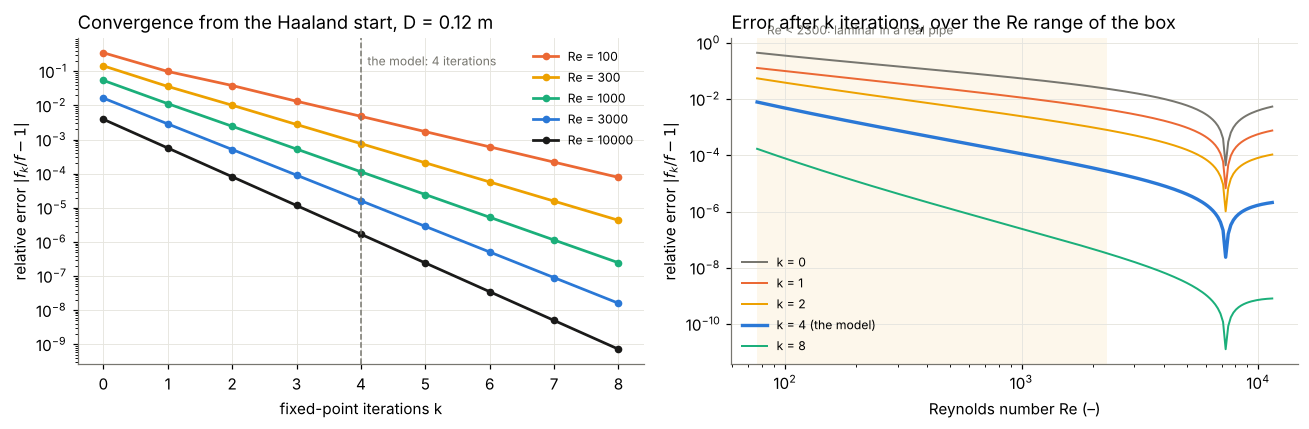

Re =      76: relative error of f after 4 iterations = 7.8e-03
Re =    2000: relative error of f after 4 iterations = 3.5e-05
Re =   11459: relative error of f after 4 iterations = 2.1e-06


In [3]:
def g_np(x, Re, D):
    return -2.0 * np.log10(EPS / (3.7 * D) + 2.51 * x / Re)


def f_iterate(Re, D, k):
    x = -1.8 * np.log10((EPS / D / 3.7) ** 1.11 + 6.9 / Re)
    for _ in range(k):
        x = g_np(x, Re, D)
    return 1.0 / x**2


def f_colebrook(Re, D):
    return 1.0 / brentq(lambda x: x - g_np(x, Re, D), 0.1, 50.0, xtol=1e-14) ** 2


re_min = 4 * RHO * 1e-3 / (np.pi * MU * 0.3)  # smallest Q, largest D
re_max = 4 * RHO * 1e-2 / (np.pi * MU * 0.02)  # largest Q, smallest D
print(f"Reynolds numbers in the box: {re_min:.0f} to {re_max:.0f}")

D0 = 0.12
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ks = np.arange(9)
for Re, col in zip([100, 300, 1000, 3000, 1e4], [ORANGE, YELLOW, AQUA, BLUE, INK]):
    fe = f_colebrook(Re, D0)
    ax1.semilogy(ks, [abs(f_iterate(Re, D0, k) / fe - 1) for k in ks], "o-", color=col, ms=4, lw=1.8, label=f"Re = {Re:g}")
ax1.axvline(4, color=MUTED, ls="--", lw=1)
ax1.text(4.1, 0.15, "the model: 4 iterations", color=MUTED, fontsize=8)
ax1.set_xlabel("fixed-point iterations k")
ax1.set_ylabel(r"relative error $|f_k/f - 1|$")
ax1.set_title(f"Convergence from the Haaland start, D = {D0} m", loc="left")
ax1.legend(frameon=False, fontsize=8)

res = np.geomspace(re_min, re_max, 200)
fex = np.array([f_colebrook(R, D0) for R in res])
for k, col in zip([0, 1, 2, 4, 8], [MUTED, ORANGE, YELLOW, BLUE, AQUA]):
    err = np.abs(np.array([f_iterate(R, D0, k) for R in res]) / fex - 1)
    ax2.loglog(res, err, color=col, lw=2.2 if k == 4 else 1.3, label=f"k = {k}" + (" (the model)" if k == 4 else ""))
ax2.axvspan(re_min, 2300, color=YELLOW, alpha=0.08, lw=0)
ax2.text(re_min * 1.1, 2.0, "Re < 2300: laminar in a real pipe", fontsize=8, color=MUTED)
ax2.set_xlabel("Reynolds number Re (–)")
ax2.set_ylabel(r"relative error $|f_k/f - 1|$")
ax2.set_title("Error after k iterations, over the Re range of the box", loc="left")
ax2.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

for Re in (re_min, 2000, re_max):
    print(f"Re = {Re:7.0f}: relative error of f after 4 iterations = {abs(f_iterate(Re, D0, 4) / f_colebrook(Re, D0) - 1):.1e}")

Each iteration multiplies the error by roughly $|g'|$, so the error falls geometrically (straight lines in the
left panel). The contraction is weakest at low $Re$, where $x = 1/\sqrt f$ is small: there 4 iterations leave an
error in $f$ of the order printed above, while at the high end of the range the error is far below the solver
tolerance. The dip in the right panel is where the Haaland start happens to cross the exact value. The 4-iteration
model is therefore a slightly different function from the implicit equation, and the two optima below differ by
about that much.

One caveat about the physics: most of this box has $Re < 2300$, where real pipe flow is laminar and $f = 64/Re$,
not Colebrook. The model applies Colebrook everywhere; the example is about the loop, not about hydraulics.

**jaxglobal.** The objective is passed as it stands.

In [4]:
r_pipe_jax = solve_jax(pipe, [1e-3, 0.02], [1e-2, 0.3])
table([r_pipe_jax])

,solver,obj,bound,time,status
0,jaxglobal,-2664.45898,-2664.592123,6.42,optimal


**Pyomo.** There is no loop construct that is part of the model. Two honest options:

* unroll the iteration in Python, as an expression (what jaxglobal's export does, see the end of this notebook),
  producing a deeply nested expression;
* add $x = 1/\sqrt f$ as a variable and impose the Colebrook equation itself as a constraint,

  $$ x + 2\log_{10}\!\left(\frac{\varepsilon}{3.7D} + \frac{2.51\,x}{Re(Q,D)}\right) = 0, \qquad 1 \le x \le 20. $$

  This is the standard approach, and it is exact (no fixed iteration count), but it adds a variable and a
  nonconvex equality to the model.

The second is written below. Note the two models are therefore not identical: Pyomo solves the implicit equation
exactly, jaxglobal approximates it with 4 iterations.

In [5]:
def pipe_pyomo():
    m = pyo.ConcreteModel()
    m.Q = pyo.Var(bounds=(1e-3, 1e-2), initialize=5e-3)
    m.D = pyo.Var(bounds=(0.02, 0.3), initialize=0.1)
    m.x = pyo.Var(bounds=(1.0, 20.0), initialize=5.0)  # 1/sqrt(f)
    v = 4 * m.Q / (np.pi * m.D**2)
    Re = RHO * v * m.D / MU
    m.colebrook = pyo.Constraint(expr=m.x == -2.0 * pyo.log10(EPS / (3.7 * m.D) + 2.51 * m.x / Re))
    dP = (1.0 / m.x**2) * (LEN / m.D) * RHO * v**2 / 2
    m.obj = pyo.Objective(expr=-4e5 * m.Q + 0.8 * dP * m.Q / 0.7 + 2.4e4 * m.D**1.5)
    return m


size_pipe = model_size(pipe_pyomo())
print(f"Pyomo: {size_pipe[0]} variables, {size_pipe[1]} constraint")
rows_pipe = [solve_pyomo(pipe_pyomo(), s) for s in ("scip", "couenne", "baron")] + [r_pipe_jax]
table(rows_pipe)

Pyomo: 3 variables, 1 constraint


,solver,obj,bound,time,status
0,scip,-2664.474807,-2664.676876,0.18,optimal
1,couenne,-2664.469916,NaN,0.44,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,-2664.458980,-2664.592123,6.42,optimal


**Reading the result.** The objectives agree to the accuracy of the 4-iteration approximation. The friction
factor enters only the pumping term, so the relative difference between the jaxglobal and SCIP objectives (printed
below) should be about the error of $f$ after 4 iterations at the optimum's Reynolds number, scaled down by the
ratio of pumping cost to the objective. Pyomo's version has a different (arguably better) property, an exact friction factor, at the price of an
additional nonconvex constraint for the solver to branch on. In jaxglobal the iteration count is a modelling
choice you control.

The figure shows where the optimum lies. The flow rate is at its upper bound: along the valley of best diameters
the objective keeps decreasing with $Q$, so the extra revenue outweighs the extra pumping cost everywhere in the
range. The diameter balances pumping against pipe cost (right panel). The orange line is $Re = 2300$; the optimum lies above it, in the region the caveat above is about.

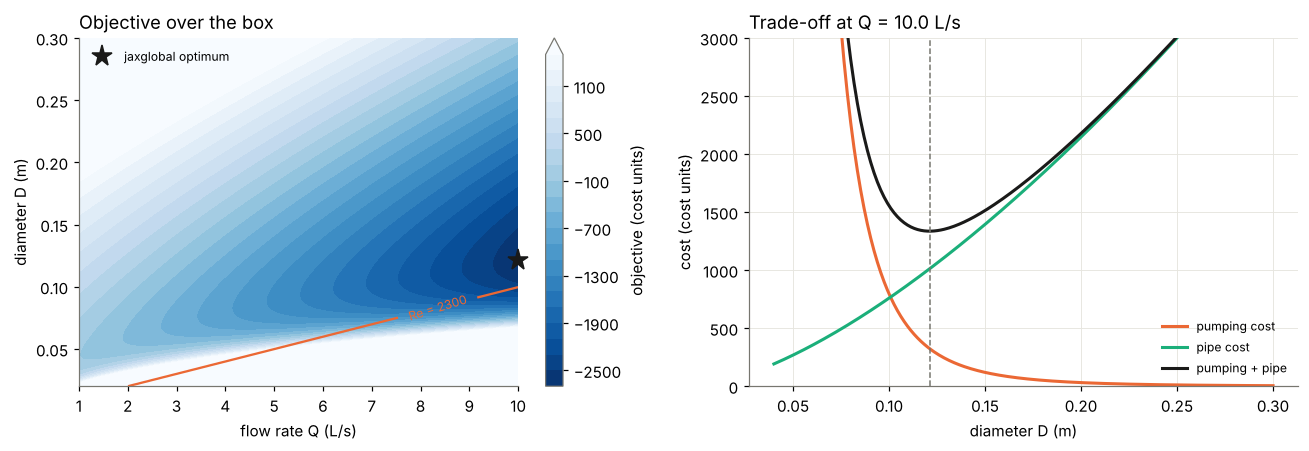

jaxglobal optimum: Q = 10.00 L/s, D = 0.1211 m, Re = 1892
pumping cost / |objective| = 0.122
relative error of f after 4 iterations at this point: 3.9e-05
relative difference of the objectives, jaxglobal vs SCIP: 5.9e-06


In [6]:
def pipe_parts(x):  # the terms of pipe(), for plotting
    Q, D = x[0], x[1]
    v = 4 * Q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    dP = friction(Re, D) * (LEN / D) * RHO * v**2 / 2
    return jnp.stack([-4e5 * Q, 0.8 * dP * Q / 0.7, 2.4e4 * D**1.5, Re])


xq, xd = r_pipe_jax["x"]
QQ, DD = np.meshgrid(np.linspace(1e-3, 1e-2, 121), np.linspace(0.02, 0.3, 141))
parts = np.asarray(jax.jit(jax.vmap(pipe_parts))(jnp.asarray(np.c_[QQ.ravel(), DD.ravel()]))).T.reshape(4, *QQ.shape)
F = parts[:3].sum(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
cs = ax1.contourf(QQ * 1e3, DD, F, levels=np.linspace(-2700, 1500, 22), cmap="Blues_r", extend="max")
fig.colorbar(cs, ax=ax1, label="objective (cost units)")
c = ax1.contour(QQ * 1e3, DD, parts[3], levels=[2300], colors=[ORANGE], linewidths=1.5)
ax1.clabel(c, fmt="Re = 2300", fontsize=8)
ax1.plot(xq * 1e3, xd, "*", color=INK, ms=14, clip_on=False, label="jaxglobal optimum")
ax1.set_xlabel("flow rate Q (L/s)")
ax1.set_ylabel("diameter D (m)")
ax1.set_title("Objective over the box", loc="left")
ax1.legend(frameon=False, fontsize=8, loc="upper left")
ax1.grid(False)

dd = np.linspace(0.04, 0.3, 300)
S = np.asarray(jax.vmap(pipe_parts)(jnp.asarray(np.c_[np.full_like(dd, xq), dd])))
ax2.plot(dd, S[:, 1], color=ORANGE, lw=2, label="pumping cost")
ax2.plot(dd, S[:, 2], color=AQUA, lw=2, label="pipe cost")
ax2.plot(dd, S[:, 1] + S[:, 2], color=INK, lw=2, label="pumping + pipe")
ax2.axvline(xd, color=MUTED, ls="--", lw=1)
ax2.set_ylim(0, 3000)
ax2.set_xlabel("diameter D (m)")
ax2.set_ylabel("cost (cost units)")
ax2.set_title(f"Trade-off at Q = {xq * 1e3:.1f} L/s", loc="left")
ax2.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

re_opt = float(pipe_parts(jnp.asarray(r_pipe_jax["x"]))[3])
print(f"jaxglobal optimum: Q = {xq * 1e3:.2f} L/s, D = {xd:.4f} m, Re = {re_opt:.0f}")
pump_share = float(pipe_parts(jnp.asarray(r_pipe_jax["x"]))[1] / abs(r_pipe_jax["obj"]))
print(f"pumping cost / |objective| = {pump_share:.3f}")
print(f"relative error of f after 4 iterations at this point: {abs(f_iterate(re_opt, xd, 4) / f_colebrook(re_opt, xd) - 1):.1e}")
if np.isfinite(rows_pipe[0]["obj"]):
    print(f"relative difference of the objectives, jaxglobal vs SCIP: {abs(r_pipe_jax['obj'] / rows_pipe[0]['obj'] - 1):.1e}")

**What jaxglobal does with the loop, and a problem.** A certified bound is only as good as the relaxation of
the function that was actually written. A simple test: on a box of width $10^{-9}$ around a point, the McCormick
relaxation must collapse onto the function value. The cell below compares, at three points, the function value
with 4 iterations and with 1 iteration, and the relaxation of `pipe` on such a tiny box. As a reference it also
relaxes `pipe_unrolled`, the same function with the iteration written as a Python `for` loop (which the trace
unrolls into 4 copies of the body). `pipe_unrolled` is only used for this check; the model solved above is
unchanged.

In [7]:
def pipe_unrolled(x):  # pipe() with the fori_loop replaced by a Python loop (for the check below only)
    Q, D = x[0], x[1]
    v = 4 * Q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    xf = -1.8 * jnp.log10((EPS / D / 3.7) ** 1.11 + 6.9 / Re)
    for _ in range(4):
        xf = -2.0 * jnp.log10(EPS / (3.7 * D) + 2.51 * xf / Re)
    dP = (1.0 / xf**2) * (LEN / D) * RHO * v**2 / 2
    return -4e5 * Q + 0.8 * dP * Q / 0.7 + 2.4e4 * D**1.5


def pipe_iters(x, k):  # pipe() with k iterations
    Q, D = x[0], x[1]
    v = 4 * Q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    return -4e5 * Q + 0.8 * friction(Re, D, k) * (LEN / D) * RHO * v**2 / 2 * Q / 0.7 + 2.4e4 * D**1.5


print(f"{'point (Q, D)':>18} {'f, 4 iter':>11} {'f, 1 iter':>11} {'relax(pipe)':>12} {'relax(unrolled)':>16}")
for pt in ([5e-3, 0.1], [2e-3, 0.05], [float(xq), float(xd)]):
    x = jnp.asarray(pt)
    cv_loop = float(relax(pipe)(x, x - 1e-9, x + 1e-9).cv)
    cv_unr = float(relax(pipe_unrolled)(x, x - 1e-9, x + 1e-9).cv)
    print(f"({pt[0]:.4f}, {pt[1]:.4f}) {float(pipe(x)):11.3f} {float(pipe_iters(x, 1)):11.3f} {cv_loop:12.3f} {cv_unr:16.3f}")

      point (Q, D)   f, 4 iter   f, 1 iter  relax(pipe)  relax(unrolled)


(0.0050, 0.1000)   -1116.129   -1117.354    -1117.354        -1116.129
(0.0020, 0.0500)    -253.739    -257.083     -257.083         -253.739


(0.0100, 0.1211)   -2664.459   -2666.255    -2666.255        -2664.459


The relaxation of the unrolled function agrees with the 4-iteration value, as it should. The relaxation of the
`fori_loop` version agrees with the **1-iteration** value instead. jaxglobal's relaxation interpreter (and its
bound-tightening tape, which is built the same way) treats a `scan` primitive like a function call and evaluates
its body once, regardless of the trip count. For a `fori_loop` with no per-iteration inputs this runs without
error and silently bounds a different function; for a `scan` over an array (as in `jnp.polyval` below, or the
`lax.scan` in notebook 10) the shapes do not match and it fails.

So for this model the `optimal` status and the bound in the table above are not a certificate for the
4-iteration function. The objective value is genuine (the local solver and the incumbent evaluate `pipe` with
JAX), and it agrees with the Pyomo solvers to the accuracy of the iteration, but the bound comes from a relaxation
of the 1-iteration function, which differs from the 4-iteration one by as much as the first two columns show. Until the interpreter unrolls `scan`, write
fixed-count loops as Python `for` loops, which the trace unrolls; the price is a larger jaxpr and a longer
compilation.

In [8]:
save_results("12", "Colebrook fori_loop", loc(pipe_pyomo), loc(pipe, friction), size_pipe, rows_pipe,
             note="Pyomo: implicit equation; jaxglobal: 4 fixed iterations")

## 2. Reusing library functions

**Background.** Engineering models are often assembled from functions that already exist as code: property
correlations, special functions, smooth approximations of `max`, probability distributions. If those building
blocks exist as `jax.numpy` / `jax.scipy` functions (or in a library from another project written in JAX), a
jaxglobal model can call them. A Pyomo model cannot call them at all, because Pyomo expressions are not numbers;
every function has to be re-expressed with `pyo.exp`, `pyo.log`, ... or wrapped as an `ExternalFunction`
(compiled code that returns values and derivatives, but no bounds). Which library functions work in jaxglobal
depends on whether the primitives they trace to are supported. We test three, each on a small problem; failures
are printed.

* **`jnp.polyval`**: a heat-capacity-style quartic $c_p(T) = \sum_{k=0}^{4} a_k T^{4-k}$ evaluated by Horner's
  rule, inside $\min_{T\in[250,450]}\ c_p(T)\,\sin(T/80) + 0.01\,T$.
* **`jax.nn.softplus`**: $\operatorname{softplus}(u) = \log(1+e^u)$, a smooth maximum of $u$ and 0, in
  $\min_{x,y\in[-3,3]}\ \operatorname{softplus}(3x-1) + \operatorname{softplus}(x-2y) + (x-y)^2$.
* **`jax.scipy.stats.norm`**: a newsvendor model with a price-dependent demand. Demand is normal with mean
  $\mu(p) = 150 - 6p$ and standard deviation $\sigma = 20$; with order quantity $q$ and $z = (q-\mu)/\sigma$, the
  expected lost sales are $\sigma L(z)$ with the standard normal loss function

  $$ L(z) = \varphi(z) - z\,\big(1-\Phi(z)\big), $$

  expected sales are $\mu - \sigma L(z)$, and the expected profit with unit cost 3 and salvage value 1 is

  $$ \max_{q\in[0,250],\ p\in[5,20]}\ \ p\,\big(\mu - \sigma L(z)\big) + \big(q - \mu + \sigma L(z)\big) - 3q . $$

  $\Phi$ is the normal CDF, which JAX computes with `erfc`.

In [9]:
def try_solve(name, f, lo, hi):
    try:
        r = solve_jax(f, lo, hi, tlim=30)
        r["solver"] = name
        return r
    except Exception as e:  # noqa: BLE001
        print(f"{name}: {type(e).__name__}: {str(e)[:150]}")
        return {"solver": name, "obj": np.nan, "bound": np.nan, "time": np.nan, "status": f"unsupported ({type(e).__name__})"}


# NASA-style heat capacity polynomial evaluated with jnp.polyval; minimize cost-like function of T
CP_COEF = jnp.array([1.2e-9, -3.0e-6, 2.5e-3, -0.4, 80.0])


def f_polyval(x):
    return jnp.polyval(CP_COEF, x[0]) * jnp.sin(x[0] / 80.0) + 0.01 * x[0]


# jax.nn.softplus, a smooth max, from the jax library
def f_softplus(x):
    return jax.nn.softplus(3 * x[0] - 1) + jax.nn.softplus(-2 * x[1] + x[0]) + (x[0] - x[1]) ** 2


# jax.scipy normal CDF (a newsvendor expected-profit model, which needs the normal loss function)
from jax.scipy.stats import norm


def f_newsvendor(x):
    q, p = x[0], x[1]
    mu = 150.0 - 6.0 * p
    z = (q - mu) / 20.0
    short = 20.0 * (norm.pdf(z) - z * (1 - norm.cdf(z)))
    sales = mu - short
    return -(p * sales + 1.0 * (q - sales) - 3.0 * q)


rows_lib = [
    try_solve("jnp.polyval", f_polyval, [250.0], [450.0]),
    try_solve("jax.nn.softplus", f_softplus, [-3.0, -3.0], [3.0, 3.0]),
    try_solve("jax.scipy.stats.norm.cdf", f_newsvendor, [0.0, 5.0], [250.0, 20.0]),
]
table(rows_lib, extra=["nodes"])

jnp.polyval: ValueError: Cannot broadcast to shape with fewer dimensions: arr_shape=(5,) shape=()


,solver,obj,bound,time,status,nodes
0,jnp.polyval,NaN,NaN,NaN,unsupported (ValueError),NaN
1,jax.nn.softplus,0.773108,0.773036,0.87,optimal,75.0
2,jax.scipy.stats.norm.cdf,-664.459021,-664.525221,3.97,optimal,2421.0


**Reading the result.** Two of three work unchanged: `jax.nn.softplus`, and the newsvendor model built on the
normal CDF (`erfc`), certified in the number of nodes shown. `jnp.polyval` fails with a shape error. It traces to
a `scan` over the coefficient array, and jaxglobal's interpreter evaluates a `scan` body once, as found in part 1,
so the per-coefficient slice has the wrong shape. That is an implementation gap, not a fundamental limit; the
polynomial can be written as an explicit Horner expression instead.

The newsvendor solution is worth a look, because it shows what the library function bought: the expected profit
is a smooth surface in $(q, p)$ with the optimum in the interior, and the optimal order quantity sits above the
mean demand at the optimal price (a safety stock), as the critical-fractile argument predicts when the margin
$p-3$ exceeds the loss $3-1$ on unsold units.

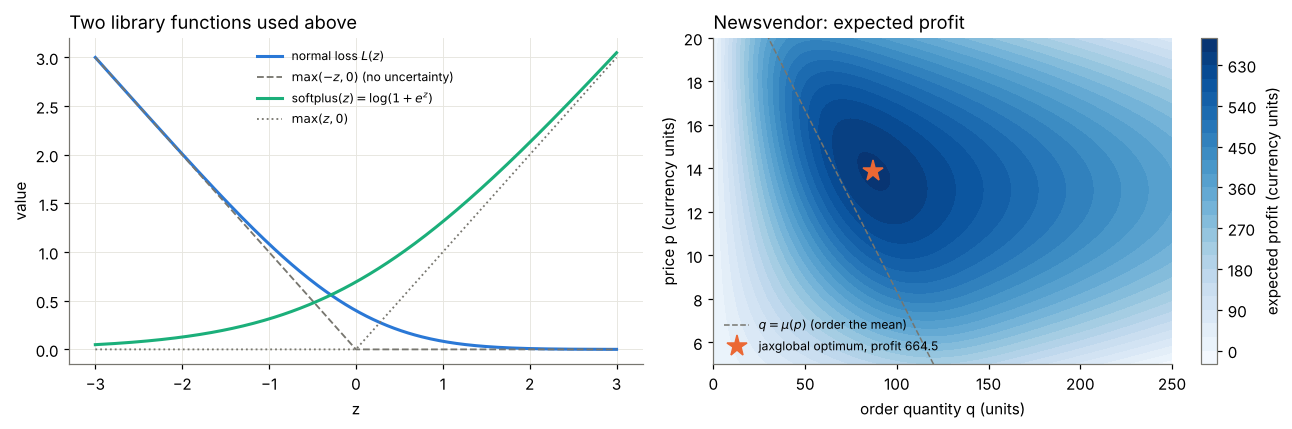

optimum: q = 87.07, p = 13.864, mean demand mu(p) = 66.82


In [10]:
r_news = rows_lib[2]
qg, pg = np.meshgrid(np.linspace(0, 250, 151), np.linspace(5, 20, 121))
profit = -np.asarray(jax.jit(jax.vmap(f_newsvendor))(jnp.asarray(np.c_[qg.ravel(), pg.ravel()]))).reshape(qg.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
zz = np.linspace(-3, 3, 301)
ax1.plot(zz, np.asarray(norm.pdf(zz) - zz * (1 - norm.cdf(zz))), color=BLUE, lw=2, label=r"normal loss $L(z)$")
ax1.plot(zz, np.maximum(-zz, 0), color=MUTED, lw=1.2, ls="--", label=r"$\max(-z, 0)$ (no uncertainty)")
ax1.plot(zz, np.asarray(jax.nn.softplus(zz)), color=AQUA, lw=2, label=r"softplus$(z)=\log(1+e^z)$")
ax1.plot(zz, np.maximum(zz, 0), color=MUTED, lw=1.2, ls=":", label=r"$\max(z, 0)$")
ax1.set_xlabel("z")
ax1.set_ylabel("value")
ax1.set_title("Two library functions used above", loc="left")
ax1.legend(frameon=False, fontsize=8)
cs = ax2.contourf(qg, pg, profit, levels=24, cmap="Blues")
fig.colorbar(cs, ax=ax2, label="expected profit (currency units)")
ax2.plot(150 - 6 * pg[:, 0], pg[:, 0], color=MUTED, lw=1, ls="--", label=r"$q = \mu(p)$ (order the mean)")
if np.isfinite(r_news["obj"]):
    ax2.plot(*r_news["x"], "*", color=ORANGE, ms=14, label=f"jaxglobal optimum, profit {-r_news['obj']:.1f}")
ax2.set_xlabel("order quantity q (units)")
ax2.set_ylabel("price p (currency units)")
ax2.set_title("Newsvendor: expected profit", loc="left")
ax2.legend(frameon=False, fontsize=8, loc="lower left")
ax2.grid(False)
fig.tight_layout()
plt.show()
if np.isfinite(r_news["obj"]):
    q_opt, p_opt = r_news["x"]
    print(f"optimum: q = {q_opt:.2f}, p = {p_opt:.3f}, mean demand mu(p) = {150 - 6 * p_opt:.2f}")

The Pyomo-side work would be the same either way: no `jnp` function can be called from Pyomo at all. `softplus`
and the polynomial are easy to retype with `pyo.log`, `pyo.exp` and products. The normal CDF is not: Pyomo has no
`erf` or normal-CDF function, so one would write a hand-made approximation of $\Phi$ (a rational or polynomial
fit, which changes the model) or an `ExternalFunction`, which no global solver here can then bound.

In [11]:
save_results("12", "library functions", None, None, (None, None), rows_lib,
             note="Pyomo cannot call jnp functions; jaxglobal works if primitives are supported")

## 3. Vectorized linear algebra

**Background.** Much numerical code is written with arrays rather than index sets: a quadratic form is `x @ Q @ x`,
a contraction is an `einsum`. The test problem is dense vector/matrix code with no index sets,

$$ \min_{x\in[-2,2]^3}\ \ x^\top Q x + \sum_i \sin(3x_i) \;=\; \sum_{i=1}^{3}\sum_{j=1}^{3} x_i\,Q_{ij}\,x_j + \sum_{i=1}^{3}\sin(3x_i), $$

with a fixed positive semidefinite $Q = BB^\top/3$ and $B$ a random $3\times3$ matrix (seed 0; the example is
synthetic). The quadratic part is convex; the sines make the problem nonconvex, with several local minima.

**What each side writes.** In jaxglobal the index notation above is literally the code:
`einsum("i,ij,j->", x, Q, x)`. In Pyomo the same sum is written over a `RangeSet`, and the generator expands it
into $3^2$ product terms when the model is built.

In [12]:
rng = np.random.default_rng(0)
Bm = rng.standard_normal((3, 3))
Qm = Bm @ Bm.T / 3


def quad(x):
    return jnp.einsum("i,ij,j->", x, Qm, x) + jnp.sum(jnp.sin(3 * x))


def quad_pyomo():
    m = pyo.ConcreteModel()
    m.I = pyo.RangeSet(0, 2)
    m.x = pyo.Var(m.I, bounds=(-2, 2), initialize=0.0)
    m.obj = pyo.Objective(expr=sum(Qm[i, j] * m.x[i] * m.x[j] for i in m.I for j in m.I) + sum(pyo.sin(3 * m.x[i]) for i in m.I))
    return m


print("eigenvalues of Q:", np.round(np.linalg.eigvalsh(Qm), 4))
print(jax.make_jaxpr(quad)(jnp.zeros(3)).pretty_print(use_color=False))

eigenvalues of Q: [0.0362 0.1821 1.1032]
{ lambda a:f64[3,3]; b:f64[3]. let
    c:f64[3] = dot_general[
      dimension_numbers=(([0], [0]), ([], []))
      preferred_element_type=float64
    ] b a
    d:f64[] = dot_general[
      dimension_numbers=(([0], [0]), ([], []))
      preferred_element_type=float64
    ] b c
    e:f64[3] = mul 3.0:f64[] b
    f:f64[3] = sin e
    g:f64[] = reduce_sum[axes=(0,) out_sharding=None] f
    h:f64[] = add d g
  in (h,) }


The jaxpr shows what jaxglobal relaxes: the `einsum` becomes two `dot_general` primitives, a matrix-vector product
with the constant $Q$ (linear in $x$, so its relaxation is exact) and an inner product of $x$ with $Qx$, followed
by an elementwise `sin` and a `reduce_sum`. jaxglobal supports `dot_general` between two variable-dependent arrays
only for 1-D inner products, which is what this is.

In [13]:
size_quad = model_size(quad_pyomo())
rows_quad = [solve_pyomo(quad_pyomo(), s) for s in ("scip", "couenne", "baron")] + [solve_jax(quad, [-2.0] * 3, [2.0] * 3)]
table(rows_quad)

,solver,obj,bound,time,status
0,scip,-2.794131,-2.794172,0.14,optimal
1,couenne,-2.794131,NaN,0.21,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,-2.794131,-2.794266,0.85,optimal


In [14]:
save_results("12", "einsum quadratic + sin", loc(quad_pyomo), loc(quad), size_quad, rows_quad, note="3 variables")
print(f"lines of model code: Pyomo {loc(quad_pyomo)}, jaxglobal {loc(quad)}")

lines of model code: Pyomo 6, jaxglobal 2


**Reading the result.** Pyomo is fine here: the double sum is easy to write and the solvers that ran agree on the
optimum. The difference is that the jaxglobal version has no index sets, so the same function works for any
dimension (`Qm` of size $n$) with no rewriting, whereas in Pyomo the problem size is baked into the `RangeSet` and
the expression generation. For large $n$, Pyomo's expression-generation time and memory (the double sum has $n^2$
terms) become the issue, while jaxglobal's cost depends on the number of traced operations, which for the
`einsum` does not grow with $n$. We do not test large $n$ here.

## 4. A parametric family

**Background.** Design studies and sensitivity analyses solve the same model for many values of a parameter.
Here: minimize the six-hump camel function plus a linear tilt,

$$ f^*(p) = \min_{x\in[-3,3],\ y\in[-2,2]}\ \Big(4 - 2.1x^2 + \tfrac{x^4}{3}\Big)x^2 + xy + (-4+4y^2)\,y^2 + p\,(x+y). $$

jaxglobal has no batching of independent solves (no GPU claim is made here): the family is a Python loop over
`minimize` calls. Each solve is a separate B&B run. We pass $p$ as a third variable fixed by `lo == hi`, so the
traced function is the same for every value; this avoids recompilation. (Closing over a new Python constant for
each value would give a new function, and a new trace and compilation, each time.)

In [15]:
def camel_p(z):
    x, y, p = z[0], z[1], z[2]
    return (4 - 2.1 * x**2 + x**4 / 3) * x**2 + x * y + (-4 + 4 * y**2) * y**2 + p * (x + y)


PS = [0.0, 0.5, 1.0]
rows_fam = []
for p in PS:
    r = solve_jax(camel_p, [-3.0, -2.0, p], [3.0, 2.0, p])
    r["solver"] = f"jaxglobal p={p}"
    rows_fam.append(r)
table(rows_fam)

,solver,obj,bound,time,status
0,jaxglobal p=0.0,-1.031628,-1.031691,1.29,optimal
1,jaxglobal p=0.5,-1.364570,-1.364621,0.16,optimal
2,jaxglobal p=1.0,-1.739532,-1.739584,0.19,optimal


Pyomo does this naturally with a mutable `Param`: build the model once, change the value, and solve again (a
solver call writes a new file each time, but the model is not rebuilt).

In [16]:
def camel_pyomo_param():
    m = pyo.ConcreteModel()
    m.p = pyo.Param(initialize=0.0, mutable=True)
    m.x = pyo.Var(bounds=(-3, 3), initialize=0.5)
    m.y = pyo.Var(bounds=(-2, 2), initialize=0.5)
    m.obj = pyo.Objective(expr=(4 - 2.1 * m.x**2 + m.x**4 / 3) * m.x**2 + m.x * m.y + (-4 + 4 * m.y**2) * m.y**2 + m.p * (m.x + m.y))
    return m


mp = camel_pyomo_param()
rows_fam_pyo = []
for p in PS:
    mp.p = p
    r = solve_pyomo(mp, "scip")
    r["solver"] = f"scip p={p}"
    rows_fam_pyo.append(r)
table(rows_fam_pyo)

,solver,obj,bound,time,status
0,scip p=0.0,-1.031628,-1.031711,0.23,optimal
1,scip p=0.5,-1.364569,-1.364629,0.14,optimal
2,scip p=1.0,-1.739532,-1.739533,0.13,optimal


In [17]:
save_results("12", "parametric family (3 values)", loc(camel_pyomo_param), loc(camel_p), model_size(camel_pyomo_param()), rows_fam_pyo + rows_fam,
             note="loop over parameter values; no batching")

**The whole curve.** Because the compiled solver is reused, a denser sweep is cheap. The cell below solves the
family for 21 values $p\in[-1,1]$ (these extra solves are not part of the saved comparison). Two properties of
$f^*(p)$ are known in advance and make a useful check on the solutions:

* $f^*$ is the pointwise minimum over $(x,y)$ of functions that are affine in $p$, so it is **concave** in $p$;
* where the minimizer is unique, its slope is the derivative of the objective with respect to $p$ at the
  minimizer (the envelope theorem), $\;\mathrm d f^*/\mathrm dp = x^*(p) + y^*(p)$.

At $p=0$ the camel function has two global minimizers, symmetric under $(x,y)\mapsto(-x,-y)$, with opposite
$x+y$; the tilt picks one of them, so $f^*$ has a kink there and the minimizer jumps.

statuses: ['optimal']
time per solve: median 0.17 s, max 0.21 s (first solve of the family above: 1.29 s, including compilation)


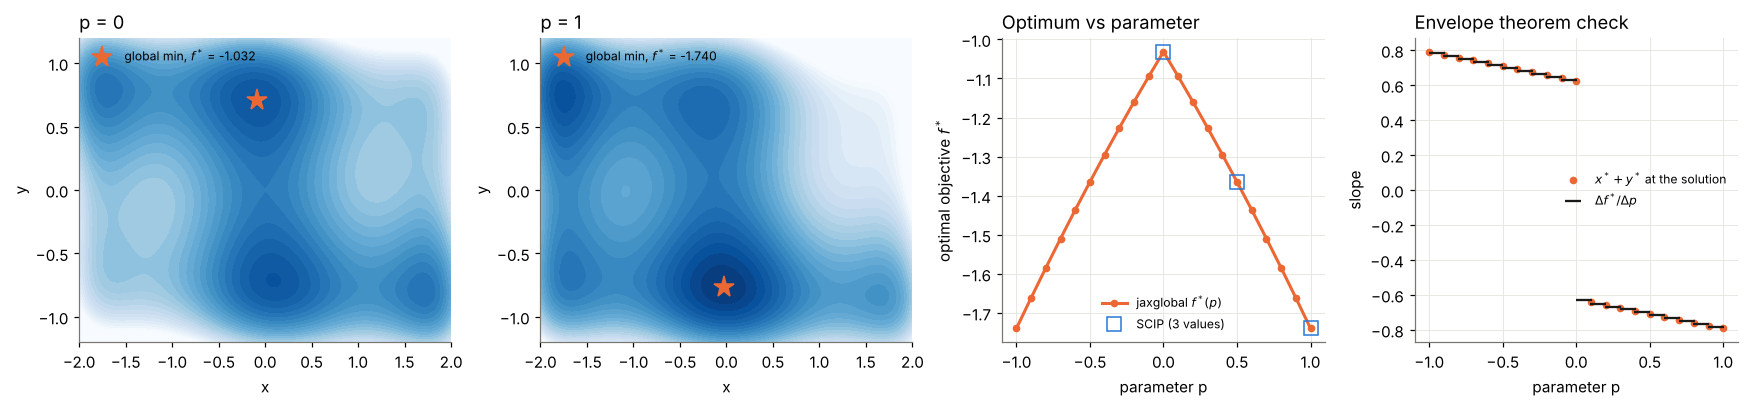

largest certified gap f* - bound over the sweep: 1.1e-04


In [18]:
P_SWEEP = np.round(np.linspace(-1.0, 1.0, 21), 10)
sweep = [solve_jax(camel_p, [-3.0, -2.0, p], [3.0, 2.0, p]) for p in P_SWEEP]
f_star = np.array([r["obj"] for r in sweep])
gap = np.array([r["obj"] - r["bound"] for r in sweep])
xy_sum = np.array([r["x"][0] + r["x"][1] for r in sweep])
t_sweep = np.array([r["time"] for r in sweep])
print("statuses:", sorted(set(r["status"] for r in sweep)))
print(f"time per solve: median {np.median(t_sweep):.2f} s, max {t_sweep.max():.2f} s "
      f"(first solve of the family above: {rows_fam[0]['time']:.2f} s, including compilation)")

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.15, 1.15, 1, 1]})
G1, G2 = np.meshgrid(np.linspace(-2, 2, 161), np.linspace(-1.2, 1.2, 121))
for ax, p in zip(axs[:2], [0.0, 1.0]):
    Z = np.asarray(jax.vmap(camel_p)(jnp.asarray(np.c_[G1.ravel(), G2.ravel(), np.full(G1.size, p)]))).reshape(G1.shape)
    ax.contourf(G1, G2, Z, levels=np.linspace(-2, 5, 29), cmap="Blues_r", extend="max")
    k = int(np.argmin(np.abs(P_SWEEP - p)))
    ax.plot(*sweep[k]["x"][:2], "*", color=ORANGE, ms=14, label=f"global min, $f^*$ = {f_star[k]:.3f}")
    ax.set_title(f"p = {p:g}", loc="left")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.grid(False)
ax = axs[2]
ax.plot(P_SWEEP, f_star, "o-", color=ORANGE, ms=4, lw=2, label="jaxglobal $f^*(p)$")
ax.plot(PS, [r["obj"] for r in rows_fam_pyo], "s", color=BLUE, mfc="none", ms=9, label="SCIP (3 values)")
ax.set_xlabel("parameter p")
ax.set_ylabel("optimal objective $f^*$")
ax.set_title("Optimum vs parameter", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower center")
ax = axs[3]
mid = 0.5 * (P_SWEEP[1:] + P_SWEEP[:-1])
ax.plot(P_SWEEP, xy_sum, "o", color=ORANGE, ms=4, label="$x^* + y^*$ at the solution")
ax.plot(mid, np.diff(f_star) / np.diff(P_SWEEP), "_", color=INK, ms=10, mew=1.5, label=r"$\Delta f^* / \Delta p$")
ax.set_xlabel("parameter p")
ax.set_ylabel("slope")
ax.set_title("Envelope theorem check", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

print(f"largest certified gap f* - bound over the sweep: {gap.max():.1e}")

**Reading the figure.** The two contour plots show what the tilt does: at $p = 0$ the two deepest wells are
equally deep, and at $p = 1$ the well with $x + y < 0$ is lowered and the other raised. The optimum curve is
concave and symmetric with a kink at $p = 0$, and the finite-difference slopes (black ticks) lie on $x^*+y^*$
(orange) everywhere except across the kink, where the slope jumps from one well's value to the other's. SCIP gives
the same optimum at the three values it solved. Every solve of the sweep is certified to the gap printed above.

## Times and lines of code

A summary of the comparisons that ran in this notebook. Times include writing the model file for the Pyomo
solvers and tracing and compilation for jaxglobal; they come from one run on a shared machine and are only
indicative. BARON appears only when GAMS is installed. For the parametric family the time is the total for the
three parameter values.

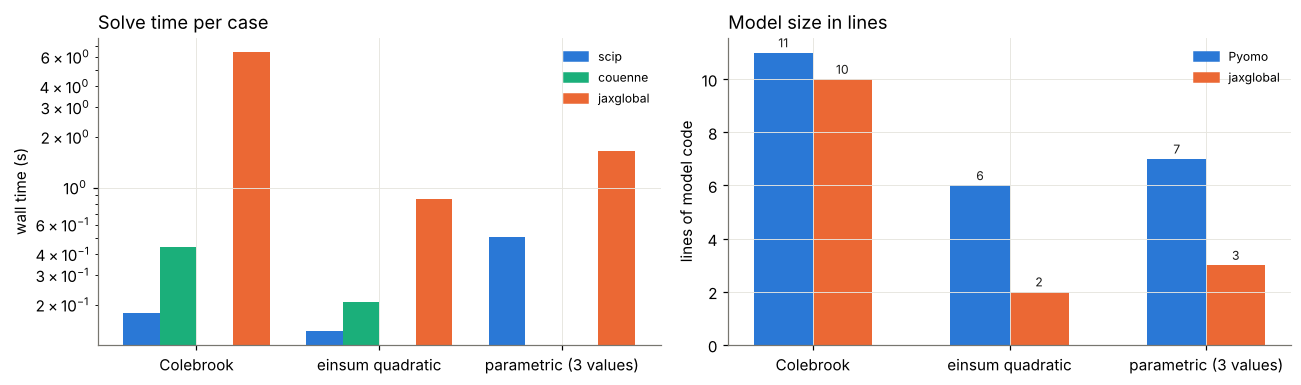

In [19]:
cases = {
    "Colebrook": rows_pipe,
    "einsum quadratic": rows_quad,
    "parametric (3 values)": [
        dict(solver="scip", time=sum(r["time"] for r in rows_fam_pyo)),
        dict(solver="jaxglobal", time=sum(r["time"] for r in rows_fam)),
    ],
}
loc_cases = {"Colebrook": (loc(pipe_pyomo), loc(pipe, friction)), "einsum quadratic": (loc(quad_pyomo), loc(quad)),
             "parametric (3 values)": (loc(camel_pyomo_param), loc(camel_p))}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
w = 0.2
for i, (case, rows) in enumerate(cases.items()):
    for j, s in enumerate(STYLE):
        t = next((r["time"] for r in rows if r["solver"] == s), np.nan)
        if np.isfinite(t):
            ax1.bar(i + (j - 1.5) * w, t, w, color=STYLE[s][0])
ax1.set_yscale("log")
ax1.set_xticks(range(len(cases)), list(cases))
ax1.set_ylabel("wall time (s)")
ax1.set_title("Solve time per case", loc="left")
ran = [s for s in STYLE if any(r["solver"] == s and np.isfinite(r["time"]) for rows in cases.values() for r in rows)]
ax1.legend([plt.Rectangle((0, 0), 1, 1, color=STYLE[s][0]) for s in ran], ran, frameon=False, fontsize=8)
for i, (case, (lp, lj)) in enumerate(loc_cases.items()):
    ax2.bar(i - 0.15, lp, 0.3, color=BLUE)
    ax2.bar(i + 0.15, lj, 0.3, color=ORANGE)
    ax2.text(i - 0.15, lp + 0.2, str(lp), ha="center", fontsize=8, color=INK)
    ax2.text(i + 0.15, lj + 0.2, str(lj), ha="center", fontsize=8, color=INK)
ax2.set_xticks(range(len(loc_cases)), list(loc_cases))
ax2.set_ylabel("lines of model code")
ax2.set_title("Model size in lines", loc="left")
ax2.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE)], ["Pyomo", "jaxglobal"], frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## What the export path does with these models

`jaxglobal.export` takes the same JAX functions and writes a SCIP model or an AMPL `.nl` file, so that SCIP,
Couenne or BARON can solve them without a hand-written Pyomo twin. It has its own symbolic walker of the jaxpr,
separate from the relaxation interpreter: it unrolls `scan` / `fori_loop` (and `while_loop`s whose condition is a
constant), translates each operation exactly or by an exact identity, reformulates `where` / comparisons with
auxiliary variables, and refuses, naming the primitive, what it cannot represent. `export.inspect` reports what it
would do without building anything; the cell below runs it on every model in this notebook.

In [20]:
for name, f, lo, hi in [("Colebrook (fori_loop)", pipe, [1e-3, 0.02], [1e-2, 0.3]),
                        ("jnp.polyval", f_polyval, [250.0], [450.0]),
                        ("jax.nn.softplus", f_softplus, [-3.0, -3.0], [3.0, 3.0]),
                        ("newsvendor (norm.cdf)", f_newsvendor, [0.0, 5.0], [250.0, 20.0]),
                        ("einsum quadratic", quad, [-2.0] * 3, [2.0] * 3)]:
    print(f"--- {name}")
    print(export.inspect(f, np.array(lo), np.array(hi), target="scip"))

--- Colebrook (fori_loop)
export to SCIP: 2 variables (+0 auxiliary, 0 binary), 0 constraints (+0), 57 operations
  exact: add x7, div x14, log x5, mul x26, pow x5
  note: scan iterations unrolled: 4
--- jnp.polyval
export to SCIP: 1 variables (+0 auxiliary, 0 binary), 0 constraints (+0), 13 operations
  exact: add x5, div x1, mul x6, sin x1
  note: scan iterations unrolled: 5
--- jax.nn.softplus
export to SCIP: 2 variables (+0 auxiliary, 0 binary), 0 constraints (+0), 24 operations
  exact: abs x2, add x5, exp x2, mul x2, neg x2, pow x1, sub x2
  rewritten: log1p x2 -> log(1 + x)
  rewritten: max x2 -> (a + b + |a - b|) / 2
  assumption: x != x taken as False (isnan of a model value is False)
--- newsvendor (norm.cdf)
export to SCIP: 2 variables (+0 auxiliary, 0 binary), 0 constraints (+0), 0 operations
  exact: abs x1, add x3, div x2, exp x1, mul x7, neg x1, pow x1, sub x8
  reformulated: gt x1 -> binary z with big-M: z=1 => u <= v, z=0 => u >= v
  reformulated: lt x1 -> binary z wit

The export unrolls the Colebrook loop (4 iterations, as the report notes) and also the `scan` inside
`jnp.polyval`, the two things the relaxation interpreter gets wrong. `softplus` traces to `max(u, 0)` plus
`log1p(exp(-|u|))`, which are written as the exact identities `(a + b + |a - b|)/2` and `log(1 + ...)`. The
newsvendor model is refused because SCIP has no `erf`/`erfc`.
So for the Colebrook model, exporting to SCIP is today the way to get a certified bound on the 4-iteration
function. The README's export section and `notebooks/export_scip.py` describe the rest.

## What was hard

**Worked in jaxglobal**
* `jax.nn.softplus`, the normal-CDF newsvendor model, the einsum quadratic and the parametric loop were solved and
  certified, each written as the plain function. The jaxglobal versions are shorter than the Pyomo ones (see the
  line counts above); for Colebrook the two are also not equivalent (implicit equation versus a fixed iteration).
* The `fori_loop` model ran and returned the right objective value, but see the next list: its bound is not a
  certificate.

**Did not work, or worked only partly**
* `lax.fori_loop` / `lax.scan`: jaxglobal's relaxation and bound-tightening interpreter evaluates the body of a
  `scan` once. A fixed-count `fori_loop` is therefore silently relaxed as a single iteration (part 1), and a
  `scan` over an array fails with a shape error (`jnp.polyval` here, the `lax.scan` in notebook 10). Write such
  loops as Python `for` loops, which the trace unrolls.
* Library functions are only reusable when every primitive they trace to is supported. `jnp.polyval` fails for the
  reason above; `jax.nn.softplus` and the normal CDF work.
* Solver coverage of functions differs between solvers. In earlier runs with BARON available (through GAMS), it
  returned no solution for the sine-containing einsum quadratic, while SCIP and Couenne solved it; BARON is not
  installed for every run of this notebook, in which case its rows read "not run".
* Parametric families are a Python loop. Passing the parameter as a fixed variable (`lo == hi`) worked: the first
  solve paid the compile cost and the later ones were much faster (see the times printed in part 4). Closing over
  a new Python constant for each value would retrace the function.
* Loops whose trip count or body depends on the variables (`while_loop`, `lax.cond` on a model value) are not
  supported at all, in the solver or in the export.

**What a Pyomo user does instead**
* Colebrook: the implicit equation as a constraint (done above).
* Library functions: re-express with Pyomo functions, or an `ExternalFunction` (which global solvers cannot bound).
* Families: `Param(mutable=True)` and a Python loop (done above), which is as simple as in jaxglobal and does not
  suffer from the compile cost.
* `jaxglobal.export.to_scip` / `to_nl` write a SCIP or `.nl` model straight from a JAX function (unrolling fixed
  loops, rewriting `tanh`/`softplus`, reformulating `where`/`max`) and refuse what they cannot represent, such as
  `erfc` or variable-dependent loops. That removes the hand translation for the supported subset; see the cell
  above and `notebooks/export_scip.py`.

**Verdict.** The advantage of the function-based approach is real for models written as numerical code, but this
notebook shows that it applies to the subset of JAX that the interpreter supports, and that a model which runs is
not automatically a model that is bounded correctly: check loops in particular. For models with many integer or
logical decisions, many constraints or large sparse structure, Pyomo remains the better choice.